# AIA temperature-resolved coronal plasma mapping

## Problem, observations and physics

Optically thin emission obeys $d_c=\int R_c(T)\xi(T)\,dT$, where $d_c$ is channel count rate, $R_c$ the independently supplied instrument/plasma response, and $\xi$ differential emission measure in cm$^{-5}$ K$^{-1}$. Twenty logarithmic bins use midpoint quadrature $K_{tc}=R_c(T_t)T_t\log(10^{\Delta\log_{10}T_t})$. Six broad channels leave temperature structure underdetermined. The local whitened SVD evaluates Tikhonov inverses and selects regularization by the discrepancy principle, then relaxes the target to remove negative bins. It propagates vertical errors and temperature resolution.

These are real 2014 synoptic observations and a genuine calibration response, with no available physical DEM truth. The supplied channel error is the author example convention 10% of rate plus 1 DN/s/pixel, not a complete detector-noise model. Some positivity-relaxed pixels have chi-square/channel above one; all such residuals are retained. The review retains input channels, temperature maps, DEM curves, counts comparisons and uncertainty information, and extends the tiny author central patch to a 48x48 active-region ROI.

## Visual contract and evidence roles

The main plate shows native observations and fresh physical reconstruction with honest common scales. Mechanism panels compare actual algorithm components and ablations; sensitivity panels quantify regularization/detail tradeoffs. References are independently captured original-code measurements on exactly these observations, never relabeled as fresh computation. Every displayed fresh variant is calculated in this execution. The private gallery exports vector PDF/SVG and high-resolution PNG from these exact arrays.

In [1]:
from pathlib import Path
import os,sys,time,json
for variable in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']: os.environ[variable]='1'
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.preprocessing import load_data
from src.main import run
from src.visualization import review,metrics
print('Kernel executable:',sys.executable)
print('NumPy version:',np.__version__)
started=time.perf_counter()
data=load_data(ROOT/'data/raw_data.npz')
fresh=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as f: upstream={k:f[k].copy() for k in f.files}
for key in fresh:
    ncc,nrmse=metrics(fresh[key],upstream[key])
    print(f'{key}: NCC={ncc:.16g}, dynamic-range NRMSE={nrmse:.16g}')
print(f'Fresh standard reconstruction: {time.perf_counter()-started:.3f} s')
# Distinct source-run scalar measurements are retained without redundant large arrays.
with np.load(ROOT/'notebooks/reference_outputs/upstream_summary.npz',allow_pickle=False) as f:
    original_summary={k:float(f[k][0]) for k in f.files}
fresh_summary={}
for key,array in fresh.items():
    value=array.astype(float)
    for statistic,number in [('mean',value.mean()),('rms',np.sqrt(np.mean(value**2))),('minimum',value.min()),('maximum',value.max())]:
        fresh_summary[key+'_'+statistic]=np.array([number])
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_summary.npz',**fresh_summary)
display(Markdown('| Measurement | Original code run | Fresh local run |\n| --- | ---: | ---: |\n'+'\n'.join(f'| {key} | {number:.10g} | {float(fresh_summary[key][0]):.10g} |' for key,number in original_summary.items())))


Kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
NumPy version: 2.4.6
reconstruction: NCC=1, dynamic-range NRMSE=0
Fresh standard reconstruction: 1.132 s


| Measurement | Original code run | Fresh local run |
| --- | ---: | ---: |
| reconstruction_mean | 3.22225413e+20 | 3.22225413e+20 |
| reconstruction_rms | 5.949908219e+20 | 5.949908219e+20 |
| reconstruction_minimum | 1.931838231e+14 | 1.931838231e+14 |
| reconstruction_maximum | 5.038528021e+21 | 5.038528021e+21 |

## Fresh reconstruction, comparisons and sensitivity

The following four figures are produced from local modules. The metric table distinguishes algorithm agreement from observational-consistency diagnostics. A low discrepancy or agreement with a standard method does not establish physical accuracy when independent truth is unavailable.

### 01 observations

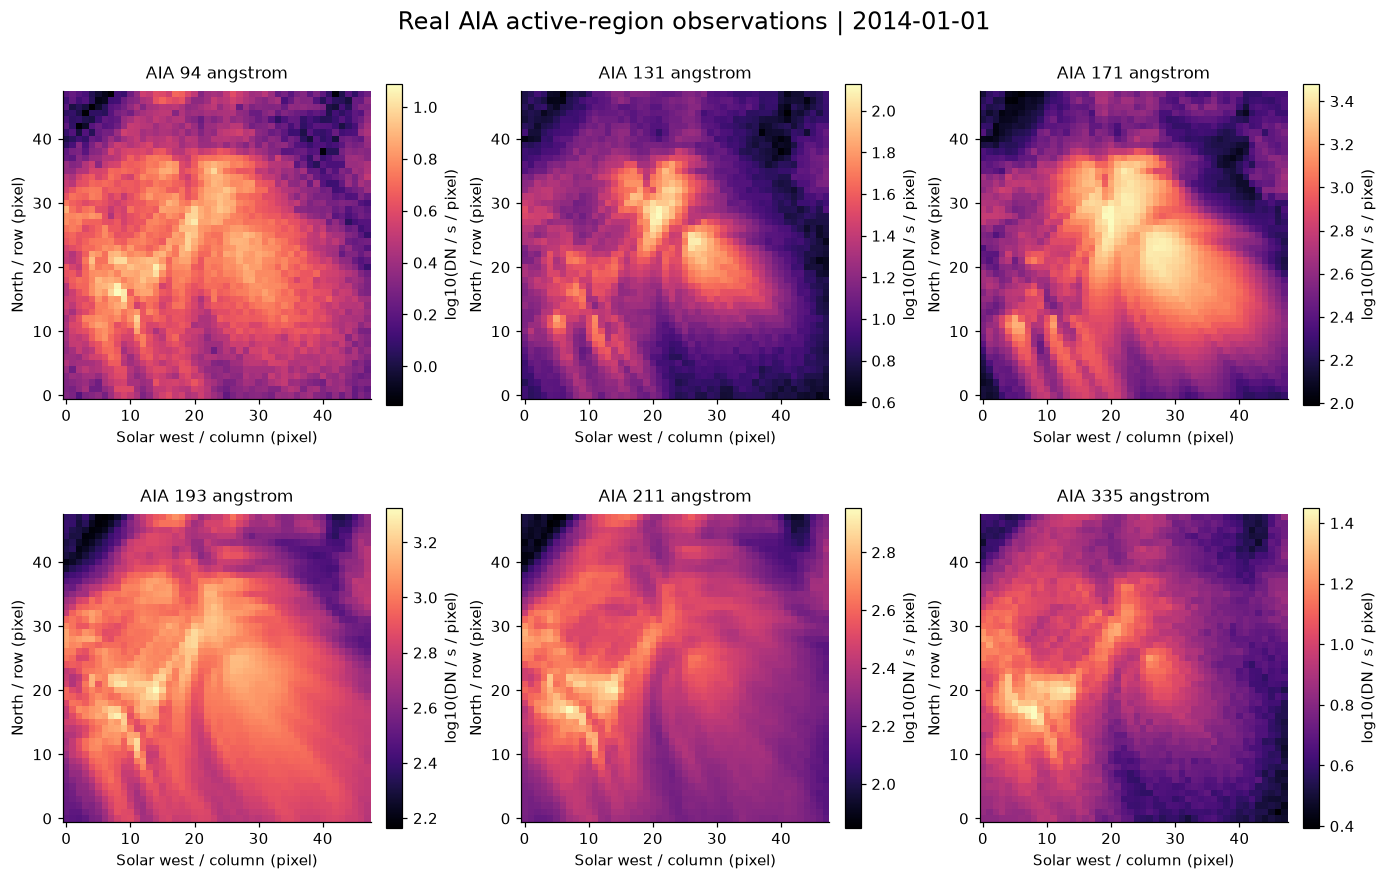

### 02 thermal maps

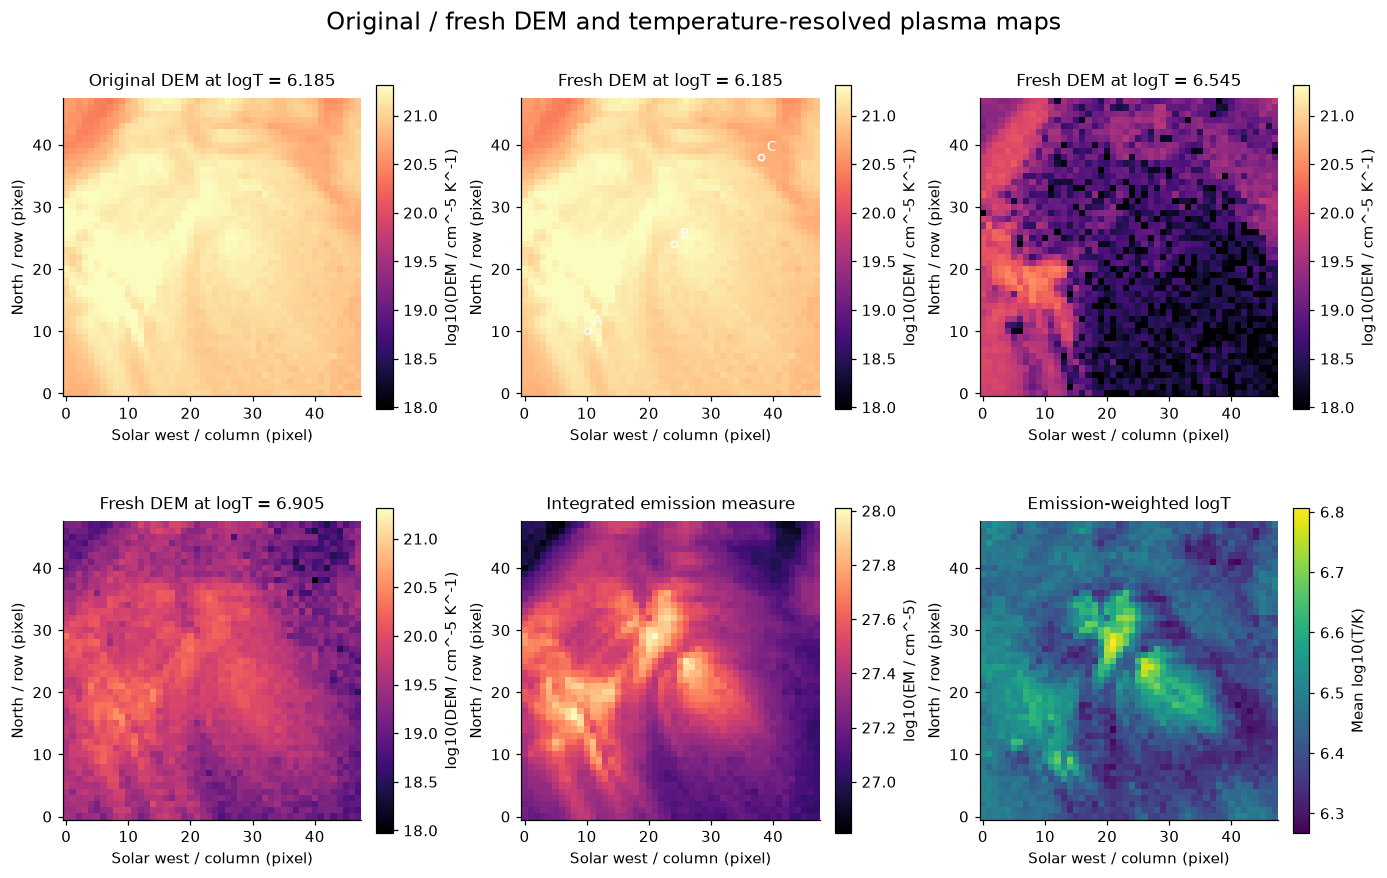

### 03 uncertainty closure

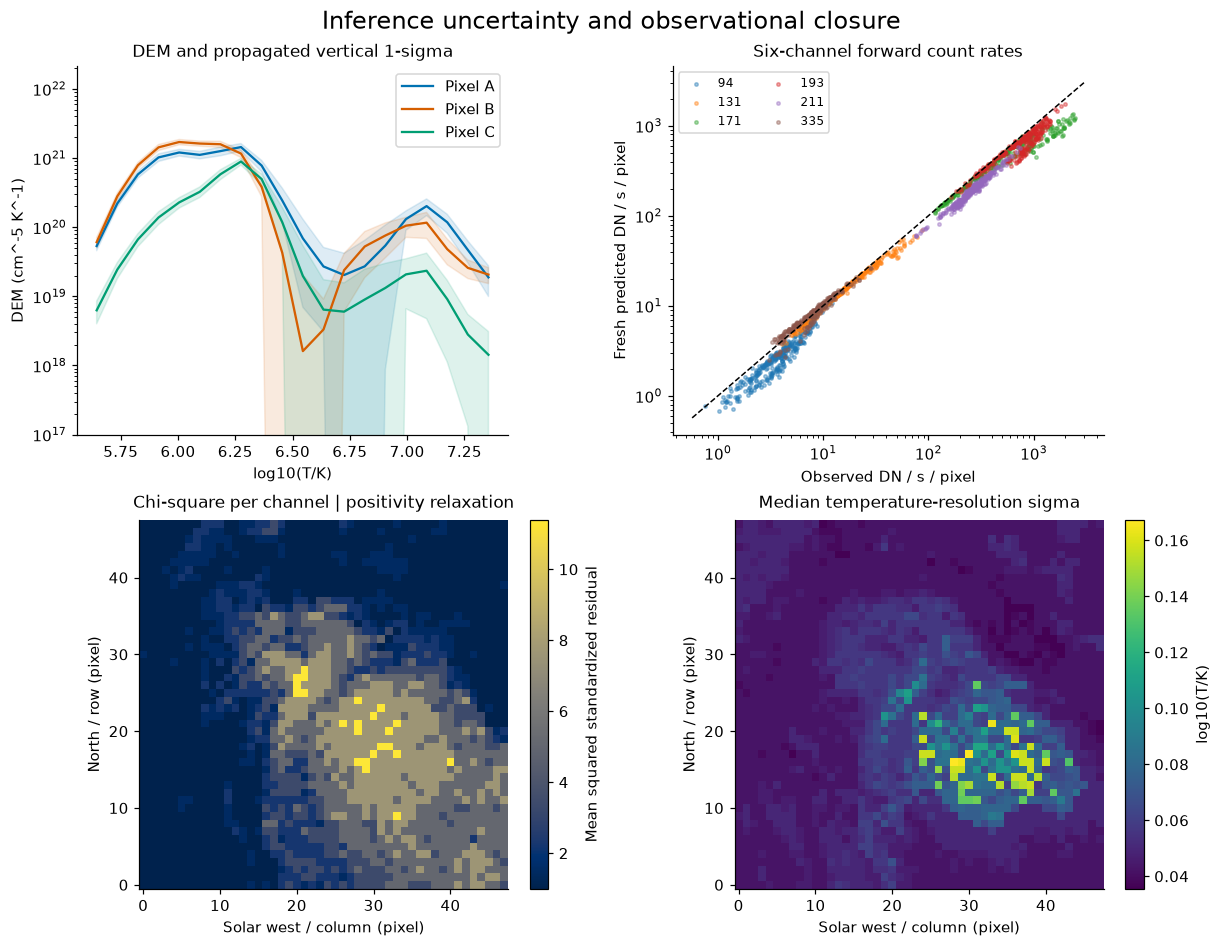

### 04 regularization

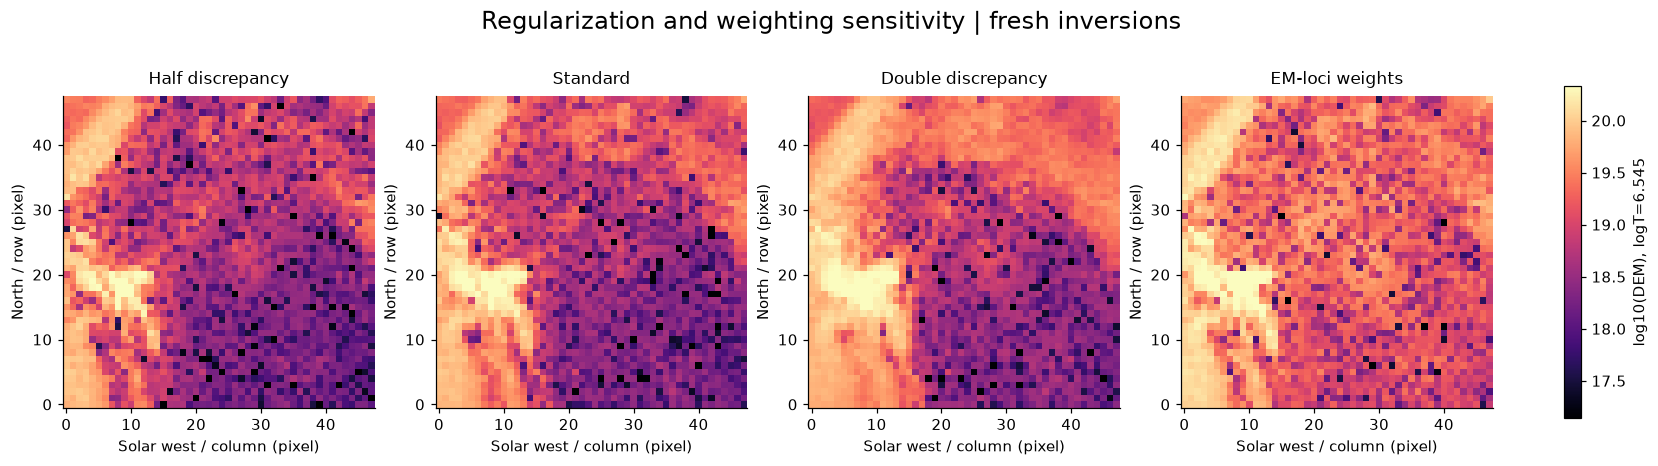

| experiment | NCC_vs_original | NRMSE_vs_original | mean_chi2_per_channel | negative_bins |
| --- | --- | --- | --- | --- |
| Half discrepancy | 0.99824177 | 0.0074852653 | 2.8514464 | 0 |
| Standard | 1 | 0 | 2.9987725 | 0 |
| Double discrepancy | 0.9972999 | 0.010150259 | 3.538737 | 0 |
| EM-loci weights | 0.99341496 | 0.014721114 | 3.7013211 | 0 |

Full active reconstruction plus experiments/figures: 7.468 s


In [2]:
figures,table,source_arrays=review(data,upstream)
for figure_name,figure in figures:
    display(Markdown('### '+figure_name.replace('_',' ')))
    display(figure)
    plt.close(figure)
keys=list(table[0])
lines=['| '+' | '.join(keys)+' |','| '+' | '.join(['---']*len(keys))+' |']
for row in table:
    lines.append('| '+' | '.join(str(row.get(k,'')) if not isinstance(row.get(k),float) else f'{row[k]:.8g}' for k in keys)+' |')
display(Markdown('\n'.join(lines)))
print(f'Full active reconstruction plus experiments/figures: {time.perf_counter()-started:.3f} s')
# Optional export path is private and supplied by the maintainer execution environment.
gallery=os.environ.get('IMAGING_PRIVATE_GALLERY')
if gallery:
    destination=Path(gallery)/ROOT.name;destination.mkdir(parents=True,exist_ok=True)
    for name,figure in figures:
        for ext in ['png','pdf','svg']:figure.savefig(destination/(name+'.'+ext),bbox_inches='tight')
    np.savez_compressed(destination/'figure_source_arrays.npz',**source_arrays)
    (destination/'experiment_metrics.json').write_text(json.dumps(table,indent=2,allow_nan=False))

## Evaluation and conclusion

The standalone Judge below evaluates the fresh file. Physical and mathematical validation are separate tests under `test/`. The spatial plates show what is actually constrained, while the ablations and residuals expose where method assumptions matter. Interpret the output as the declared regularized standard-method reconstruction of the supplied real observations; do not reinterpret it as independently measured truth.

In [3]:
import subprocess
result=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
print((ROOT/'output/judge_report.json').read_text())
assert result.returncode==0,result.stderr

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 0.0,
    "mean_chi2_per_channel": 2.9987725151899878
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "mean_chi2_per_channel": {
      "comparison": "<=",
      "boundary": 3.2986497667089867
    }
  },
  "errors": []
}

